In [1]:
import pandas as pd
import numpy as np

In [2]:
# dataset link: https://archive.ics.uci.edu/dataset/45/heart+disease

In [3]:
pip install ucimlrepo

Note: you may need to restart the kernel to use updated packages.


In [4]:
from ucimlrepo import fetch_ucirepo 
  
# fetch dataset 
heart_disease = fetch_ucirepo(id=45) 
  
# data (as pandas dataframes) 
X = heart_disease.data.features 
y = heart_disease.data.targets 
  
# metadata 
print(heart_disease.metadata) 
  
# variable information 
print(heart_disease.variables) 


{'uci_id': 45, 'name': 'Heart Disease', 'repository_url': 'https://archive.ics.uci.edu/dataset/45/heart+disease', 'data_url': 'https://archive.ics.uci.edu/static/public/45/data.csv', 'abstract': '4 databases: Cleveland, Hungary, Switzerland, and the VA Long Beach', 'area': 'Health and Medicine', 'tasks': ['Classification'], 'characteristics': ['Multivariate'], 'num_instances': 303, 'num_features': 13, 'feature_types': ['Categorical', 'Integer', 'Real'], 'demographics': ['Age', 'Sex'], 'target_col': ['num'], 'index_col': None, 'has_missing_values': 'yes', 'missing_values_symbol': 'NaN', 'year_of_dataset_creation': 1989, 'last_updated': 'Fri Nov 03 2023', 'dataset_doi': '10.24432/C52P4X', 'creators': ['Andras Janosi', 'William Steinbrunn', 'Matthias Pfisterer', 'Robert Detrano'], 'intro_paper': {'ID': 231, 'type': 'NATIVE', 'title': 'International application of a new probability algorithm for the diagnosis of coronary artery disease.', 'authors': 'R. Detrano, A. Jánosi, W. Steinbrunn, M

In [5]:
X

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
298,45,1,1,110,264,0,0,132,0,1.2,2,0.0,7.0
299,68,1,4,144,193,1,0,141,0,3.4,2,2.0,7.0
300,57,1,4,130,131,0,0,115,1,1.2,2,1.0,7.0
301,57,0,2,130,236,0,2,174,0,0.0,2,1.0,3.0


In [6]:
y

,num
0,0
1,2
2,1
3,0
4,0
...,...
298,1
299,2
300,3
301,1


In [7]:
data = pd.merge(X, y, left_index=True, right_index=True)
data

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,2
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
298,45,1,1,110,264,0,0,132,0,1.2,2,0.0,7.0,1
299,68,1,4,144,193,1,0,141,0,3.4,2,2.0,7.0,2
300,57,1,4,130,131,0,0,115,1,1.2,2,1.0,7.0,3
301,57,0,2,130,236,0,2,174,0,0.0,2,1.0,3.0,1


# Heart Disease: Data Cleaning & EDA

`data` is the **processed Cleveland** subset of the UCI Heart Disease dataset: one row per patient, 13 clinical features (`X`) plus the diagnosis target `num` (`y`), joined on the row index.

**Contents**
1. Data dictionary
2. Table structure, column types & keys
3. Missingness
4. Distinct values & domain checks
5. Data cleaning
6. Statistical summaries
7. Visualizations
8. Key findings

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats

## 1. Data dictionary

UCI's variable table leaves most descriptions blank, so the meanings and codes below come from the dataset's full attribute documentation (printed in the metadata above).

| Column | Meaning | Semantic type | Values / units |
|---|---|---|---|
| `age` | Age of the patient | numeric (integer) | years |
| `sex` | Sex | binary | 1 = male, 0 = female |
| `cp` | Chest pain type | nominal | 1 = typical angina, 2 = atypical angina, 3 = non-anginal pain, 4 = asymptomatic |
| `trestbps` | Resting blood pressure on admission to the hospital | numeric (integer) | mm Hg |
| `chol` | Serum cholesterol | numeric (integer) | mg/dl |
| `fbs` | Fasting blood sugar > 120 mg/dl | binary | 1 = true, 0 = false |
| `restecg` | Resting electrocardiogram result | nominal | 0 = normal, 1 = ST-T wave abnormality, 2 = probable/definite left ventricular hypertrophy (Estes' criteria) |
| `thalach` | Maximum heart rate achieved during the exercise test | numeric (integer) | beats/min |
| `exang` | Exercise-induced angina | binary | 1 = yes, 0 = no |
| `oldpeak` | ST depression induced by exercise relative to rest | numeric (continuous) | ECG depression, 0.0–6.2 (units not stated by UCI; conventionally mm) |
| `slope` | Slope of the peak exercise ST segment | ordinal | 1 = upsloping, 2 = flat, 3 = downsloping |
| `ca` | Number of major vessels colored by fluoroscopy | ordinal count | 0–3 |
| `thal` | Thallium stress test result | nominal | 3 = normal, 6 = fixed defect, 7 = reversible defect |
| `num` | **Target**: angiographic disease status | ordinal | 0 = < 50% diameter narrowing (no disease); 1–4 = > 50% narrowing in at least one major vessel (disease present) |

**Notes**
- `num` is the label. UCI notes that experiments usually only distinguish *presence* (1–4) from *absence* (0), so a binary `disease` column is added during cleaning.
- Most columns store **numeric codes for categories**. Averages of `cp`, `restecg` or `thal` don't mean anything, so treat them as categorical in analysis and modeling.
- UCI's metadata labels `oldpeak` as Integer, but it is continuous (steps of 0.1).

## 2. Table structure, column types & keys

In [9]:
print(f"X: {X.shape}, y: {y.shape}, data: {data.shape}")
data.info()

X: (303, 13), y: (303, 1), data: (303, 14)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  num       303 non-null    int64  
dtypes: float64(3), int64(11)
memory usage: 33.3 KB


In [10]:
heart_disease.variables[['name', 'role', 'type', 'units', 'missing_values']]

,name,role,type,units,missing_values
0,age,Feature,Integer,years,no
1,sex,Feature,Categorical,None,no
2,cp,Feature,Categorical,None,no
3,trestbps,Feature,Integer,mm Hg,no
4,chol,Feature,Integer,mg/dl,no
5,fbs,Feature,Categorical,None,no
6,restecg,Feature,Categorical,None,no
7,thalach,Feature,Integer,None,no
8,exang,Feature,Categorical,None,no
9,oldpeak,Feature,Integer,None,no


### Keys

The source has two tables, `X` (features) and `y` (target), in a 1:1 relationship on the row index. UCI doesn't provide a patient ID column, so the row index is the only key. The checks below confirm the merge lost no rows and that no records are duplicated.

In [11]:
print("ID column provided by UCI:", heart_disease.data.ids)
print("X and y indexes match:", X.index.equals(y.index))
print("Rows lost in merge:", len(X) - len(data))
print("Index is unique:", data.index.is_unique)
print("Duplicate rows:", data.duplicated().sum())

ID column provided by UCI: None
X and y indexes match: True
Rows lost in merge: 0
Index is unique: True
Duplicate rows: 0


### Column types

The pandas dtypes are all numeric, but that hides what each column means. `ca` and `thal` are `float64` only because they contain `NaN`. The grouping below drives the rest of the analysis.

In [ ]:
numeric_cols = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
categorical_cols = ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']
target_col = 'num'

semantic_type = (
    {col: 'numeric' for col in numeric_cols}
    | {col: 'categorical' for col in categorical_cols}
    | {target_col: 'target (ordinal)'}
)

structure = pd.DataFrame({
    'dtype': data.dtypes,
    'semantic_type': data.columns.map(semantic_type),
    'n_unique': data.nunique(),
    'n_missing': data.isna().sum(),
    'pct_missing': (data.isna().mean() * 100).round(2),
    'min': data.min(),
    'max': data.max(),
})
structure

,dtype,semantic_type,n_unique,n_missing,pct_missing,min,max
age,int64,numeric,41,0,0.00,29.0,77.0
sex,int64,categorical,2,0,0.00,0.0,1.0
cp,int64,categorical,4,0,0.00,1.0,4.0
trestbps,int64,numeric,50,0,0.00,94.0,200.0
chol,int64,numeric,152,0,0.00,126.0,564.0
fbs,int64,categorical,2,0,0.00,0.0,1.0
restecg,int64,categorical,3,0,0.00,0.0,2.0
thalach,int64,numeric,91,0,0.00,71.0,202.0
exang,int64,categorical,2,0,0.00,0.0,1.0
oldpeak,float64,numeric,40,0,0.00,0.0,6.2


## 3. Missingness

In [13]:
missing = data.isna().sum()
missing[missing > 0]

ca      4
thal    2
dtype: int64

In [14]:
data[data.isna().any(axis=1)]

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
87,53,0,3,128,216,0,2,115,0,0.0,1,0.0,NaN,0
166,52,1,3,138,223,0,0,169,0,0.0,1,NaN,3.0,0
192,43,1,4,132,247,1,2,143,1,0.1,2,NaN,7.0,1
266,52,1,4,128,204,1,0,156,1,1.0,2,0.0,NaN,2
287,58,1,2,125,220,0,0,144,0,0.4,2,NaN,7.0,0
302,38,1,3,138,175,0,0,173,0,0.0,1,NaN,3.0,0


In [15]:
# is missingness related to the target?
has_missing = data.isna().any(axis=1)
pd.DataFrame({
    'rows': has_missing.value_counts(),
    'disease_rate': (data['num'] > 0).groupby(has_missing).mean().round(2),
})

,rows,disease_rate
False,297,0.46
True,6,0.33


Only **6 of 303 rows (2%)** have a missing value: 4 in `ca` and 2 in `thal`, and no row is missing both. Both are categorical exam results, so mean imputation makes no sense, and mode imputation would invent a clinical finding. Six rows are too few to tell whether the gaps relate to the diagnosis. Because so few rows are affected, **they are dropped** during cleaning, which gives the standard 297-row Cleveland set.

## 4. Distinct values & domain checks

In [16]:
for col in categorical_cols + [target_col]:
    print(f"{col:8}", data[col].value_counts(dropna=False).sort_index().to_dict())

sex      {0: 97, 1: 206}
cp       {1: 23, 2: 50, 3: 86, 4: 144}
fbs      {0: 258, 1: 45}
restecg  {0: 151, 1: 4, 2: 148}
exang    {0: 204, 1: 99}
slope    {1: 142, 2: 140, 3: 21}
ca       {0.0: 176, 1.0: 65, 2.0: 38, 3.0: 20, nan: 4}
thal     {3.0: 166, 6.0: 18, 7.0: 117, nan: 2}
num      {0: 164, 1: 55, 2: 36, 3: 35, 4: 13}


In [17]:
# every code should be one of the values documented in the data dictionary
valid_values = {
    'sex': {0, 1},
    'cp': {1, 2, 3, 4},
    'fbs': {0, 1},
    'restecg': {0, 1, 2},
    'exang': {0, 1},
    'slope': {1, 2, 3},
    'ca': {0, 1, 2, 3},
    'thal': {3, 6, 7},
    'num': {0, 1, 2, 3, 4},
}
{col: set(data[col].dropna()) - valid for col, valid in valid_values.items()}

{'sex': set(),
 'cp': set(),
 'fbs': set(),
 'restecg': set(),
 'exang': set(),
 'slope': set(),
 'ca': set(),
 'thal': set(),
 'num': set()}

In [18]:
# zeros in these columns would be disguised missing values (the other UCI sites have chol = 0)
(data[['trestbps', 'chol', 'thalach']] == 0).sum()

trestbps    0
chol        0
thalach     0
dtype: int64

In [ ]:
q1 = data[numeric_cols].quantile(0.25)
q3 = data[numeric_cols].quantile(0.75)
iqr = q3 - q1
outliers = (data[numeric_cols] < q1 - 1.5 * iqr) | (data[numeric_cols] > q3 + 1.5 * iqr)
outliers.sum()

age         0
trestbps    9
chol        5
thalach     1
oldpeak     5
dtype: int64

In [20]:
data.loc[outliers.any(axis=1), numeric_cols + ['num']].sort_values('chol', ascending=False)

,age,trestbps,chol,thalach,oldpeak,num
152,67,115,564,160,1.6,0
48,65,140,417,157,0.8,0
181,56,134,409,150,1.9,2
121,63,150,407,154,4.0,4
173,62,140,394,157,1.2,0
231,55,180,327,117,3.4,2
201,64,180,325,154,0.0,0
285,58,114,318,140,4.4,4
191,51,140,298,122,4.2,3
126,56,200,288,133,4.0,3


- Every categorical code is valid. The only problem is rare levels: `restecg = 1` (ST-T abnormality) has just **4 patients**, and `thal = 6` (fixed defect) has 18.
- None of `trestbps`, `chol` or `thalach` has a zero, so there are no disguised missing values. `oldpeak = 0` is a real value (no ST depression).
- IQR flags a handful of high values (cholesterol up to 564 mg/dl, resting BP up to 200 mm Hg, `oldpeak` up to 6.2, one low max heart rate of 71). All are clinically possible, so they are **kept**. Removing them would throw away real patients.

## 5. Data cleaning

1. Drop the 6 rows with a missing `ca` or `thal`.
2. Cast `ca` and `thal` back to `int` (they were only `float` because of `NaN`).
3. Add a binary target `disease` = 1 if `num > 0`, the standard framing for this dataset.
4. Add an explicit primary key `patient_id`, using the original row index so every cleaned row traces back to `data`.
5. Keep outliers (see above) and keep the numeric codes. Readable labels go in a separate `labeled` frame used only for plots and tables.

In [21]:
cleaned = data.dropna().copy()
cleaned[['ca', 'thal']] = cleaned[['ca', 'thal']].astype(int)
cleaned['disease'] = (cleaned['num'] > 0).astype(int)
cleaned = cleaned.rename_axis('patient_id').reset_index()

assert cleaned.isna().sum().sum() == 0
assert cleaned['patient_id'].is_unique
print(f"{len(data)} -> {len(cleaned)} rows")
cleaned.head()

303 -> 297 rows


,patient_id,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num,disease
0,0,63,1,1,145,233,1,2,150,0,2.3,3,0,6,0,0
1,1,67,1,4,160,286,0,2,108,1,1.5,2,3,3,2,1
2,2,67,1,4,120,229,0,2,129,1,2.6,2,2,7,1,1
3,3,37,1,3,130,250,0,0,187,0,3.5,3,0,3,0,0
4,4,41,0,2,130,204,0,2,172,0,1.4,1,0,3,0,0


In [22]:
labels = {
    'sex': {0: 'female', 1: 'male'},
    'cp': {1: 'typical angina', 2: 'atypical angina', 3: 'non-anginal', 4: 'asymptomatic'},
    'fbs': {0: '<= 120 mg/dl', 1: '> 120 mg/dl'},
    'restecg': {0: 'normal', 1: 'ST-T abnormality', 2: 'LV hypertrophy'},
    'exang': {0: 'no', 1: 'yes'},
    'slope': {1: 'upsloping', 2: 'flat', 3: 'downsloping'},
    'thal': {3: 'normal', 6: 'fixed defect', 7: 'reversible defect'},
    'disease': {0: 'no disease', 1: 'disease'},
}

col_names = {
    'age': 'Age (years)',
    'sex': 'Sex',
    'cp': 'Chest pain type',
    'trestbps': 'Resting BP (mm Hg)',
    'chol': 'Cholesterol (mg/dl)',
    'fbs': 'Fasting blood sugar',
    'restecg': 'Resting ECG',
    'thalach': 'Max heart rate (bpm)',
    'exang': 'Exercise-induced angina',
    'oldpeak': 'ST depression (oldpeak)',
    'slope': 'Peak exercise ST slope',
    'ca': 'Major vessels colored (ca)',
    'thal': 'Thallium test (thal)',
}

# ordered categoricals keep the documented code order in tables and plots
labeled = cleaned.copy()
for col, mapping in labels.items():
    labeled[col] = pd.Categorical(cleaned[col].map(mapping), categories=list(mapping.values()))
labeled.head()

,patient_id,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num,disease
0,0,63,male,typical angina,145,233,> 120 mg/dl,LV hypertrophy,150,no,2.3,downsloping,0,fixed defect,0,no disease
1,1,67,male,asymptomatic,160,286,<= 120 mg/dl,LV hypertrophy,108,yes,1.5,flat,3,normal,2,disease
2,2,67,male,asymptomatic,120,229,<= 120 mg/dl,LV hypertrophy,129,yes,2.6,flat,2,reversible defect,1,disease
3,3,37,male,non-anginal,130,250,<= 120 mg/dl,normal,187,no,3.5,downsloping,0,normal,0,no disease
4,4,41,female,atypical angina,130,204,<= 120 mg/dl,LV hypertrophy,172,no,1.4,upsloping,0,normal,0,no disease


In [23]:
data.rename_axis('patient_id').to_csv('../datasets/original/heart_disease.csv')
cleaned.to_csv('../datasets/cleaned/heart_disease_cleaned.csv', index=False)

## 6. Statistical summaries

### Target balance

In [24]:
pd.DataFrame({
    'count': cleaned['num'].value_counts().sort_index(),
    'pct': (cleaned['num'].value_counts(normalize=True).sort_index() * 100).round(1),
})

,count,pct
num,,
0,160,53.9
1,54,18.2
2,35,11.8
3,35,11.8
4,13,4.4


In [25]:
labeled['disease'].value_counts().to_frame().assign(pct=lambda df: (df['count'] / df['count'].sum() * 100).round(1))

,count,pct
disease,,
no disease,160,53.9
disease,137,46.1


### Numeric features

In [26]:
numeric_summary = cleaned[numeric_cols].describe().T
numeric_summary['skew'] = cleaned[numeric_cols].skew()
numeric_summary['kurtosis'] = cleaned[numeric_cols].kurt()
numeric_summary.round(2)

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis
age,297.0,54.54,9.05,29.0,48.0,56.0,61.0,77.0,-0.22,-0.52
trestbps,297.0,131.69,17.76,94.0,120.0,130.0,140.0,200.0,0.70,0.81
chol,297.0,247.35,52.00,126.0,211.0,243.0,276.0,564.0,1.12,4.44
thalach,297.0,149.60,22.94,71.0,133.0,153.0,166.0,202.0,-0.54,-0.05
oldpeak,297.0,1.06,1.17,0.0,0.0,0.8,1.6,6.2,1.25,1.51


In [27]:
no_disease = cleaned[cleaned['disease'] == 0]
has_disease = cleaned[cleaned['disease'] == 1]

# Mann-Whitney U: compares the two groups without assuming normality (oldpeak and chol are skewed)
numeric_tests = pd.DataFrame({
    'mean_no_disease': no_disease[numeric_cols].mean(),
    'mean_disease': has_disease[numeric_cols].mean(),
    'median_no_disease': no_disease[numeric_cols].median(),
    'median_disease': has_disease[numeric_cols].median(),
    'p_value': [stats.mannwhitneyu(no_disease[col], has_disease[col]).pvalue for col in numeric_cols],
})
numeric_tests.sort_values('p_value').round({'mean_no_disease': 2, 'mean_disease': 2})

,mean_no_disease,mean_disease,median_no_disease,median_disease,p_value
thalach,158.58,139.11,161.0,142.0,1.675290e-13
oldpeak,0.60,1.59,0.2,1.4,1.538610e-12
age,52.64,56.76,52.0,58.0,3.672541e-05
trestbps,129.18,134.64,130.0,130.0,2.345960e-02
chol,243.49,251.85,235.5,253.0,4.668918e-02


### Categorical features

In [28]:
rates = pd.concat({
    col: cleaned.groupby(labeled[col], observed=True)['disease'].agg(n='count', disease_rate='mean')
    for col in categorical_cols
})
rates.index.names = ['feature', 'value']
rates.round(2)

n  disease_rate
feature value                               
sex     female              96          0.26
        male               201          0.56
cp      typical angina      23          0.30
        atypical angina     49          0.18
        non-anginal         83          0.22
        asymptomatic       142          0.73
fbs     <= 120 mg/dl       254          0.46
        > 120 mg/dl         43          0.47
restecg normal             147          0.37
        ST-T abnormality     4          0.75
        LV hypertrophy     146          0.54
exang   no                 200          0.32
        yes                 97          0.76
slope   upsloping          139          0.26
        flat               137          0.65
        downsloping         21          0.57
ca      0                  174          0.26
        1                   65          0.68
        2                   38          0.82
        3                   20          0.85
thal    normal             164          0.23
        fixed defect        18          0.67
        reversible defect  115          0.77

In [29]:
# chi-square test of independence with disease; Cramer's V as effect size (0 = none, 1 = perfect)
categorical_tests = []
for col in categorical_cols:
    table = pd.crosstab(cleaned[col], cleaned['disease'])
    chi2, p, dof, expected = stats.chi2_contingency(table)
    categorical_tests.append({
        'feature': col,
        'chi2': chi2,
        'dof': dof,
        'p_value': p,
        'cramers_v': np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1))),
        'min_expected_count': expected.min(),
    })
pd.DataFrame(categorical_tests).set_index('feature').sort_values('p_value').round({'chi2': 2, 'cramers_v': 3, 'min_expected_count': 2})

,chi2,dof,p_value,cramers_v,min_expected_count
feature,,,,,
thal,82.46,2,1.241673e-18,0.527,8.30
cp,77.28,3,1.178284e-16,0.510,10.61
ca,72.30,3,1.372578e-15,0.493,9.23
exang,50.94,1,9.510884e-13,0.414,44.74
slope,43.47,2,3.630107e-10,0.383,9.69
sex,21.85,1,2.945690e-06,0.271,44.28
restecg,9.58,2,8.331151e-03,0.180,1.85
fbs,0.00,1,1.000000e+00,0.000,19.84


`restecg` has an expected cell count below 5 because of its 4-patient `ST-T abnormality` level, so treat its chi-square p-value as approximate.

### Correlation

Spearman (rank) correlation handles the ordinal and skewed columns better than Pearson. The codes of nominal columns (`cp`, `restecg`, `thal`) have no real order, so their correlations are only rough directional signals. The chi-square tests above are the proper check for those columns.

In [30]:
corr = cleaned.drop(columns=['patient_id', 'num']).corr(method='spearman')
corr['disease'].drop('disease').sort_values(key=abs, ascending=False).round(2)

thal        0.52
ca          0.49
cp          0.46
thalach    -0.43
exang       0.42
oldpeak     0.41
slope       0.36
sex         0.28
age         0.24
restecg     0.17
trestbps    0.13
chol        0.12
fbs         0.00
Name: disease, dtype: float64

## 7. Visualizations

Colors are used the same way in every chart: **blue = no disease**, **orange = disease**.

In [31]:
BLUE, ORANGE, RED = '#2a78d6', '#eb6834', '#e34948'
SURFACE, INK, INK_2, GRID, AXIS, NEUTRAL = '#fcfcfb', '#0b0b0b', '#52514e', '#e1e0d9', '#c3c2b7', '#f0efec'
disease_palette = {'no disease': BLUE, 'disease': ORANGE}

plt.rcParams.update({
    'figure.facecolor': SURFACE,
    'axes.facecolor': SURFACE,
    'axes.edgecolor': AXIS,
    'axes.labelcolor': INK_2,
    'axes.titlecolor': INK,
    'axes.titlesize': 11,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'axes.grid.axis': 'y',
    'axes.axisbelow': True,
    'grid.color': GRID,
    'grid.linewidth': 0.8,
    'xtick.color': AXIS,
    'ytick.color': AXIS,
    'xtick.labelcolor': INK_2,
    'ytick.labelcolor': INK_2,
    'text.color': INK,
    'legend.frameon': False,
    'font.size': 10,
})


def disease_legend(fig):
    handles = [plt.Rectangle((0, 0), 1, 1, color=color) for color in disease_palette.values()]
    fig.legend(handles, disease_palette.keys(), loc='lower center', ncol=2, bbox_to_anchor=(0.5, 1.0))

### Target distribution

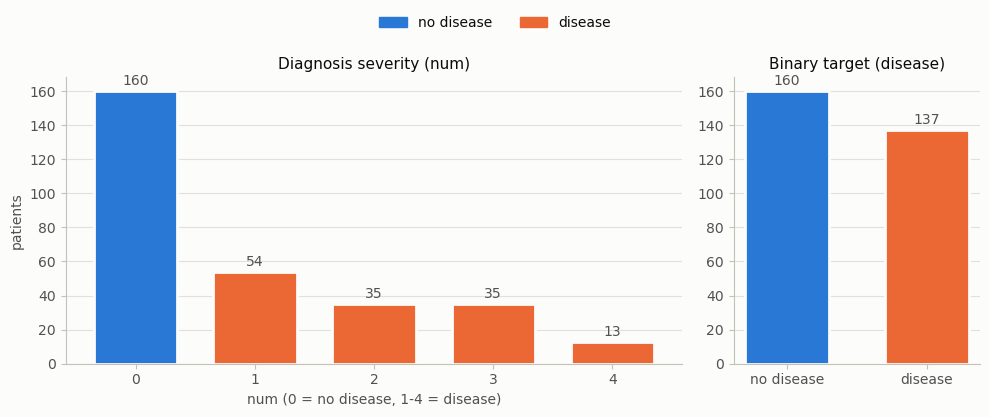

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), gridspec_kw={'width_ratios': [5, 2]})

num_counts = cleaned['num'].value_counts().sort_index()
axes[0].bar(num_counts.index, num_counts.values, color=[BLUE] + [ORANGE] * 4, width=0.7, edgecolor=SURFACE, linewidth=2)
axes[0].bar_label(axes[0].containers[0], color=INK_2, padding=2)
axes[0].set(title='Diagnosis severity (num)', xlabel='num (0 = no disease, 1-4 = disease)', ylabel='patients')

disease_counts = labeled['disease'].value_counts().reindex(disease_palette.keys())
axes[1].bar(disease_counts.index, disease_counts.values, color=list(disease_palette.values()), width=0.6, edgecolor=SURFACE, linewidth=2)
axes[1].bar_label(axes[1].containers[0], color=INK_2, padding=2)
axes[1].set(title='Binary target (disease)')

plt.tight_layout()
disease_legend(fig)
plt.show()

### Numeric distributions

The stacked histograms show each feature's overall shape (skew, outliers) and how the two groups split within it. The box plots compare the groups directly.

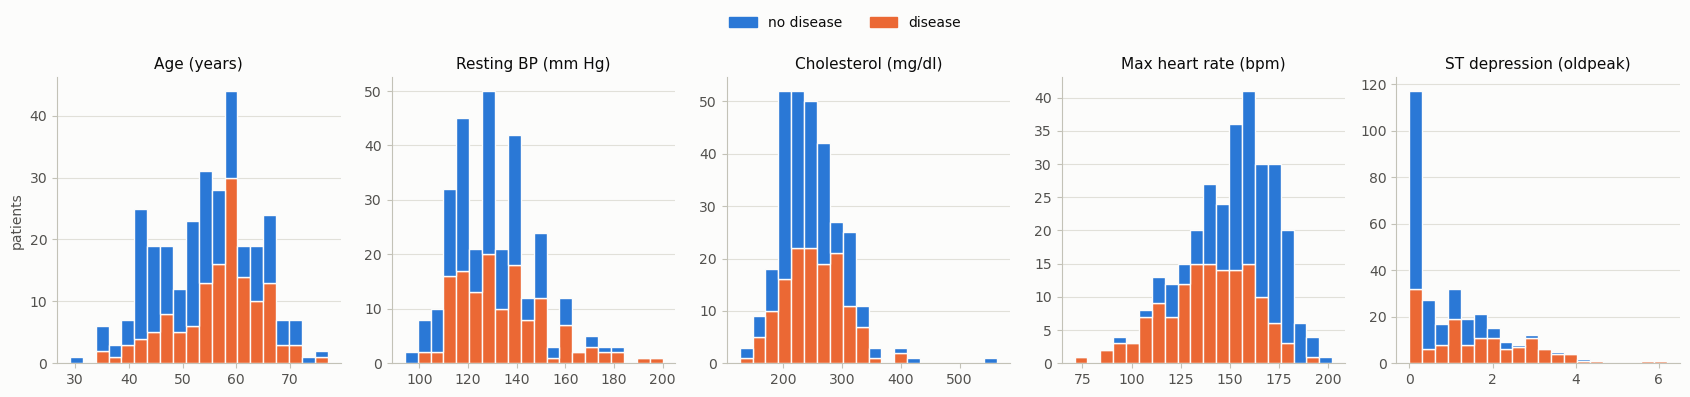

In [33]:
fig, axes = plt.subplots(1, 5, figsize=(17, 3.6))
for ax, col in zip(axes, numeric_cols):
    sns.histplot(
        data=labeled, x=col, hue='disease', hue_order=list(disease_palette), palette=disease_palette,
        multiple='stack', bins=20, edgecolor=SURFACE, linewidth=1, alpha=1, legend=False, ax=ax,
    )
    ax.set(title=col_names[col], xlabel='', ylabel='')
axes[0].set_ylabel('patients')
plt.tight_layout()
disease_legend(fig)
plt.show()

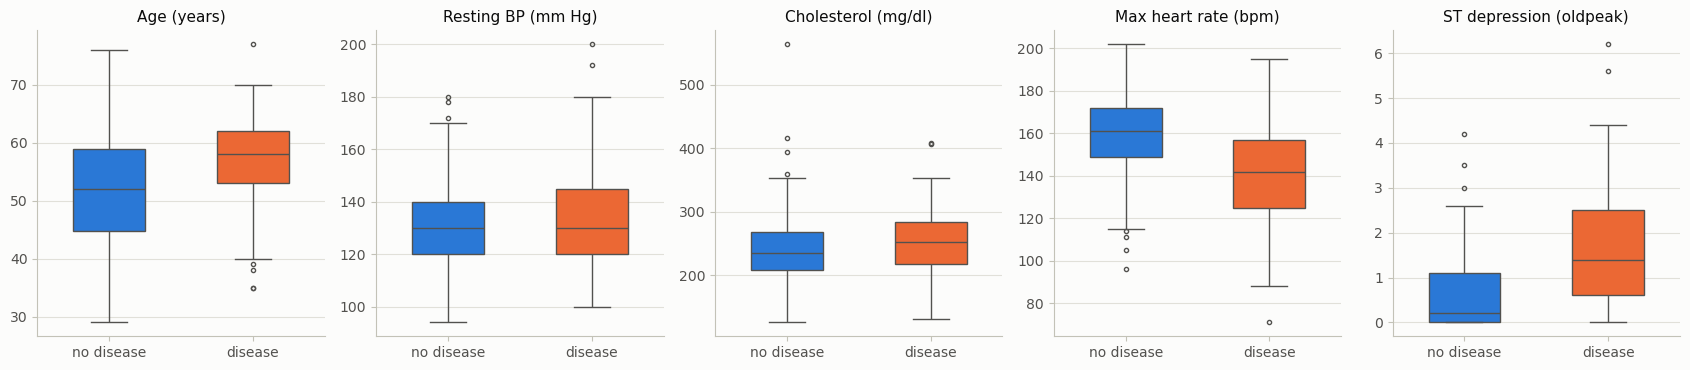

In [34]:
fig, axes = plt.subplots(1, 5, figsize=(17, 3.8))
for ax, col in zip(axes, numeric_cols):
    sns.boxplot(
        data=labeled, x='disease', y=col, hue='disease', palette=disease_palette,
        width=0.5, saturation=1, linewidth=1, linecolor=INK_2, fliersize=3, legend=False, ax=ax,
    )
    ax.set(title=col_names[col], xlabel='', ylabel='')
plt.tight_layout()
plt.show()

### Categorical features vs. disease

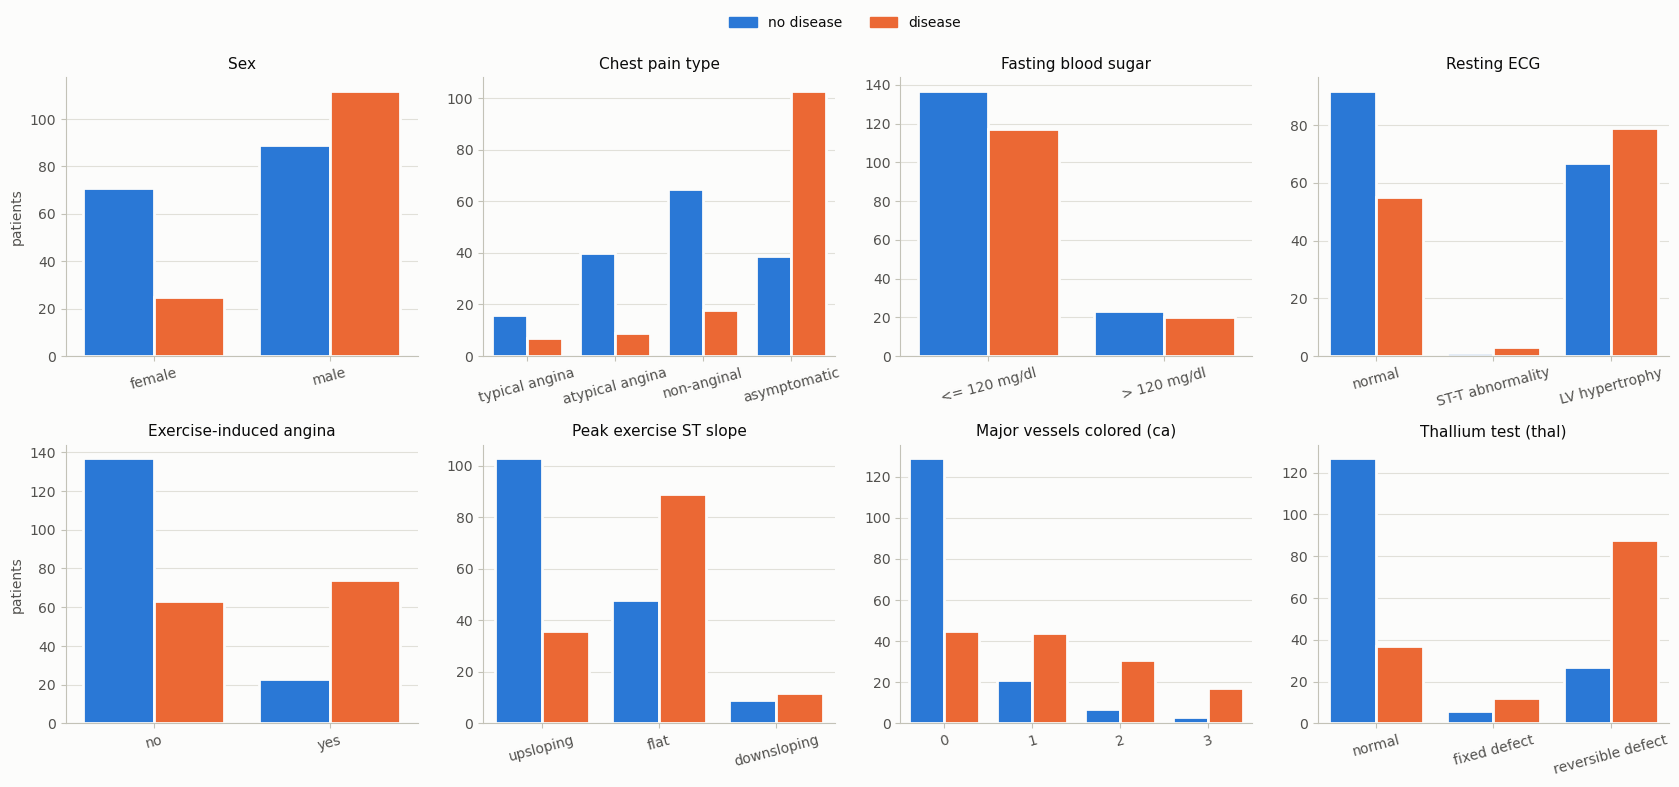

In [35]:
fig, axes = plt.subplots(2, 4, figsize=(17, 7.5))
for ax, col in zip(axes.flat, categorical_cols):
    sns.countplot(
        data=labeled, x=col, hue='disease', hue_order=list(disease_palette), palette=disease_palette,
        saturation=1, edgecolor=SURFACE, linewidth=2, legend=False, ax=ax,
    )
    ax.set(title=col_names[col], xlabel='', ylabel='')
    ax.tick_params(axis='x', labelrotation=15)
for ax in axes[:, 0]:
    ax.set_ylabel('patients')
plt.tight_layout()
disease_legend(fig)
plt.show()

### Correlation heatmap

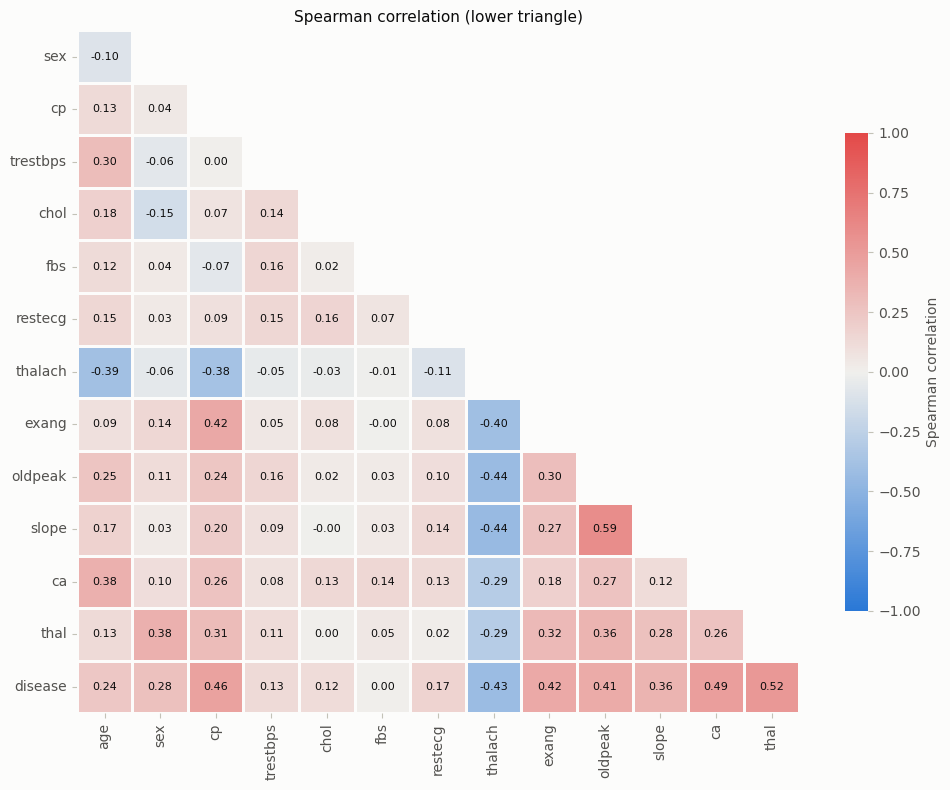

In [36]:
lower = corr.iloc[1:, :-1]
mask = np.triu(np.ones_like(lower, dtype=bool), k=1)
diverging = LinearSegmentedColormap.from_list('blue_red', [BLUE, NEUTRAL, RED])

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(
    lower, mask=mask, cmap=diverging, vmin=-1, vmax=1, center=0,
    annot=True, fmt='.2f', annot_kws={'size': 8, 'color': INK},
    linewidths=2, linecolor=SURFACE, cbar_kws={'shrink': 0.7, 'label': 'Spearman correlation'}, ax=ax,
)
ax.grid(False)
ax.set_title('Spearman correlation (lower triangle)')
plt.tight_layout()
plt.show()

### Max heart rate vs. age

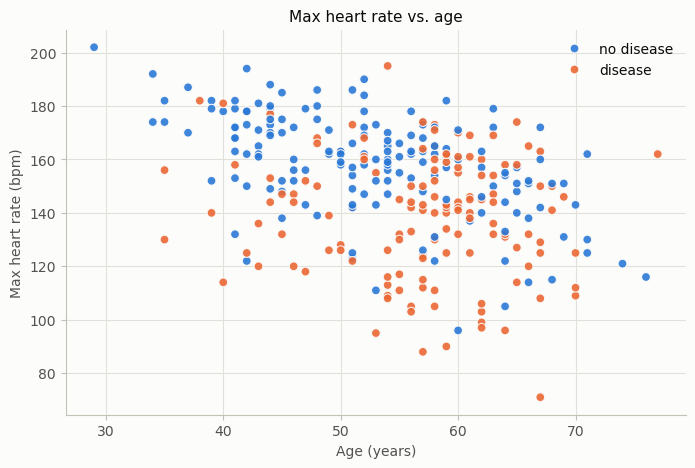

In [37]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(
    data=labeled, x='age', y='thalach', hue='disease', hue_order=list(disease_palette), palette=disease_palette,
    s=40, edgecolor=SURFACE, linewidth=0.8, alpha=0.9, ax=ax,
)
ax.grid(True, axis='both')
ax.set(title='Max heart rate vs. age', xlabel=col_names['age'], ylabel=col_names['thalach'])
ax.legend(title='')
plt.show()

## 8. Key findings

**Data quality**
- The data is clean overall: no duplicate rows, no invalid codes, and no zeros standing in for missing values. Only 6 rows (2%) had missing `ca`/`thal`, and they were dropped, leaving **297 patients**.
- Caveats: the sample is small, two-thirds of patients are male (201 of 297), and some category levels are rare (`restecg = 1` has 4 patients, `thal = 6` has 18).
- UCI provides no patient ID. The cleaned table gets a `patient_id` key equal to the original row index.

**Target**
- The binary target is roughly balanced: 160 no disease (54%) vs. 137 disease (46%). Severity levels 1–4 are thin (level 4 has only 13 patients), which is another reason to use the binary `disease` target.

**What separates disease from no disease**
- **Thallium test (`thal`)** is the strongest single signal (Cramér's V = 0.53). Disease rate is 77% for a reversible defect vs. 23% for a normal result.
- **Chest pain type (`cp`)** (V = 0.51): *asymptomatic* patients have the **highest** disease rate (73%) vs. 18–30% for the other three types. This counterintuitive pattern is a well-known quirk of this dataset.
- **Vessels colored (`ca`)** (V = 0.49): disease rate climbs steadily from 26% at 0 vessels to 85% at 3.
- **Exercise response:** exercise-induced angina (76% vs. 32%), a flat or downsloping ST slope (65% / 57% vs. 26% upsloping), lower max heart rate (median 142 vs. 161 bpm) and more ST depression (median 1.4 vs. 0.2) all go with disease (p < 0.001).
- **Age and sex:** patients with disease are older (median 58 vs. 52), and men have a much higher disease rate than women (56% vs. 26%).
- **Weak or no signal:** resting blood pressure and cholesterol differ only slightly between groups (p ≈ 0.02 and 0.05), despite being classic risk factors. Fasting blood sugar shows **no** association (46% vs. 47% disease rate, p = 1.0).

**Relationships between features**
- `oldpeak` and `slope` are the most correlated pair (ρ = 0.59); both describe the ST segment during exercise. Max heart rate falls with age (ρ = −0.39). No pair is correlated enough to be redundant.

In [38]:
# exporting data dictionary table to json
# exporting above data dictionary table to json
import json

columns = [
    {
        "column": "age",
        "meaning": "Age of the patient",
        "semantic_type": "numeric (integer)",
        "values_units": "years"
    },
    {
        "column": "sex",
        "meaning": "Sex",
        "semantic_type": "binary",
        "values_units": "1 = male, 0 = female"
    },
    {
        "column": "cp",
        "meaning": "Chest pain type",
        "semantic_type": "nominal",
        "values_units": "1 = typical angina, 2 = atypical angina, 3 = non-anginal pain, 4 = asymptomatic"
    },
    {
        "column": "trestbps",
        "meaning": "Resting blood pressure on admission to the hospital",
        "semantic_type": "numeric (integer)",
        "values_units": "mm Hg"
    },
    {
        "column": "chol",
        "meaning": "Serum cholesterol",
        "semantic_type": "numeric (integer)",
        "values_units": "mg/dl"
    },
    {
        "column": "fbs",
        "meaning": "Fasting blood sugar > 120 mg/dl",
        "semantic_type": "binary",
        "values_units": "1 = true, 0 = false"
    },
    {
        "column": "restecg",
        "meaning": "Resting electrocardiogram result",
        "semantic_type": "nominal",
        "values_units": "0 = normal, 1 = ST-T wave abnormality, 2 = probable/definite left ventricular hypertrophy (Estes' criteria)"
    },
    {
        "column": "thalach",
        "meaning": "Maximum heart rate achieved during the exercise test",
        "semantic_type": "numeric (integer)",
        "values_units": "beats/min"
    },
    {
        "column": "exang",
        "meaning": "Exercise-induced angina",
        "semantic_type": "binary",
        "values_units": "1 = yes, 0 = no"
    },
    {
        "column": "oldpeak",
        "meaning": "ST depression induced by exercise relative to rest",
        "semantic_type": "numeric (continuous)",
        "values_units": "ECG depression, 0.0–6.2 (units not stated by UCI; conventionally mm)"
    },
    {
        "column": "slope",
        "meaning": "Slope of the peak exercise ST segment",
        "semantic_type": "ordinal",
        "values_units": "1 = upsloping, 2 = flat, 3 = downsloping"
    },
    {
        "column": "ca",
        "meaning": "Number of major vessels colored by fluoroscopy",
        "semantic_type": "ordinal count",
        "values_units": "0–3"
    },
    {
        "column": "thal",
        "meaning": "Thallium stress test result",
        "semantic_type": "nominal",
        "values_units": "3 = normal, 6 = fixed defect, 7 = reversible defect"
    },
    {
        "column": "num",
        "meaning": "Target: angiographic disease status",
        "semantic_type": "ordinal",
        "values_units": "0 = < 50% diameter narrowing (no disease); 1–4 = > 50% narrowing in at least one major vessel (disease present)"
    }
]

In [39]:
with open("heart_disease_metadata.json", "w") as f:
    json.dump(columns, f, indent=4)

In [40]:
from IPython.display import FileLink
FileLink("heart_disease_metadata.json")

/Users/vaidehikarve/Documents/D37-Semantic-Data-Lake/EDA/heart_disease_metadata.json

In [41]:
with open("heart_disease_metadata.json", "r") as f:
    metadata = json.load(f)

print(metadata)

[{'column': 'age', 'meaning': 'Age of the patient', 'semantic_type': 'numeric (integer)', 'values_units': 'years'}, {'column': 'sex', 'meaning': 'Sex', 'semantic_type': 'binary', 'values_units': '1 = male, 0 = female'}, {'column': 'cp', 'meaning': 'Chest pain type', 'semantic_type': 'nominal', 'values_units': '1 = typical angina, 2 = atypical angina, 3 = non-anginal pain, 4 = asymptomatic'}, {'column': 'trestbps', 'meaning': 'Resting blood pressure on admission to the hospital', 'semantic_type': 'numeric (integer)', 'values_units': 'mm Hg'}, {'column': 'chol', 'meaning': 'Serum cholesterol', 'semantic_type': 'numeric (integer)', 'values_units': 'mg/dl'}, {'column': 'fbs', 'meaning': 'Fasting blood sugar > 120 mg/dl', 'semantic_type': 'binary', 'values_units': '1 = true, 0 = false'}, {'column': 'restecg', 'meaning': 'Resting electrocardiogram result', 'semantic_type': 'nominal', 'values_units': "0 = normal, 1 = ST-T wave abnormality, 2 = probable/definite left ventricular hypertrophy (E

In [ ]:
# this JSON file is in the data_dictionaries folder